# A04 · 01 · Sample design & alignment QC
Host-only RNA-seq, human colon organoid (donor patient 35) × *C. difficile* 630 × butyrate 0/5/10 mM.
Single donor → within-donor design. This notebook checks the design table, STAR mapping rates, and featureCounts assignment.

In [1]:
import sys, os
sys.path.insert(0, os.path.abspath('.'))   # a04_common.py next to notebooks
import a04_common as ac
import numpy as np, pandas as pd
import matplotlib.pyplot as plt
print('project root:', ac.PROJ)


project root: /storage/users/job37yv/Projects/DECIDE_A04_CdiffOrganoid_Butyrate


## Design table (derived from sample IDs)

In [2]:
meta = ac.load_meta()
display(meta)
print('\nsamples per group:')
print(meta['group'].value_counts().reindex(ac.GROUP_ORDER))

,infection,butyrate,replicate,group
sample_id,,,,
M0R1,Mock,0,1,Mock_0
M0R2,Mock,0,2,Mock_0
M0R3,Mock,0,3,Mock_0
M5R1,Mock,5,1,Mock_5
M5R2,Mock,5,2,Mock_5
M5R3,Mock,5,3,Mock_5
M10R1,Mock,10,1,Mock_10
M10R2,Mock,10,2,Mock_10
M10R3,Mock,10,3,Mock_10



samples per group:
group
Mock_0     3
Mock_5     3
Mock_10    3
Cd_0       3
Cd_5       3
Cd_10      3
Name: count, dtype: int64


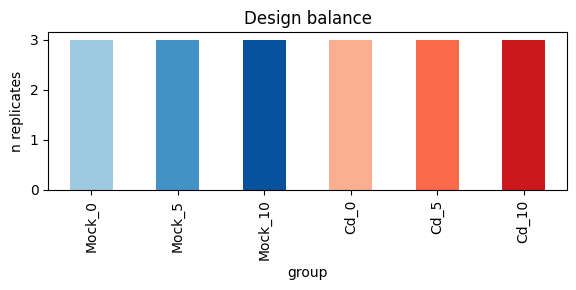

In [3]:
# design balance
ax = meta['group'].value_counts().reindex(ac.GROUP_ORDER).plot.bar(
    color=[ac.GROUP_COLORS[g] for g in ac.GROUP_ORDER], figsize=(6,3))
ax.set_ylabel('n replicates'); ax.set_title('Design balance'); plt.tight_layout(); plt.show()

## STAR alignment rates
Expect ~85–95% uniquely mapped for human polyA. Flag <80%.

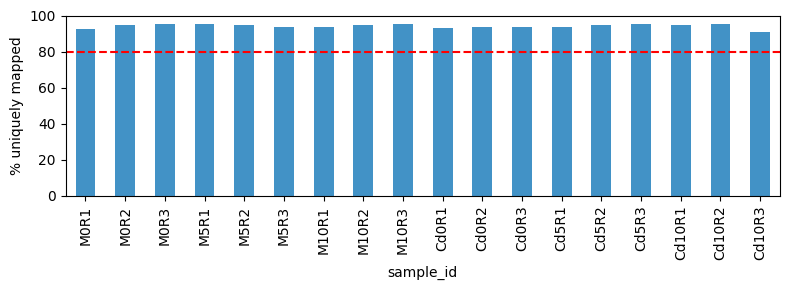

range: 90.8–95.5%
FLAG <80%: none


In [4]:
star = ac.parse_star_logs()
col = 'Uniquely mapped reads %'
rate = star[col].str.rstrip('%').astype(float).reindex(meta.index)
ax = rate.plot.bar(figsize=(8,3), color='#4292c6'); ax.axhline(80, ls='--', c='r')
ax.set_ylabel('% uniquely mapped'); ax.set_ylim(0,100); plt.tight_layout(); plt.show()
print('range: %.1f–%.1f%%' % (rate.min(), rate.max()))
print('FLAG <80%:', list(rate[rate<80].index) or 'none')

## featureCounts assignment (unstranded, -s 0)
Expect ~60–80% assigned. Low → strandedness wrong (already resolved to -s 0).

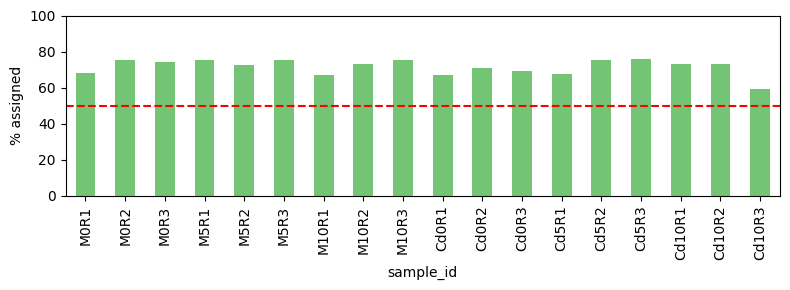

assigned range: 59.0–76.1%


In [5]:
summ = pd.read_csv(ac.TAB/'counts_raw.tsv.summary', sep='\t', index_col=0)
summ.columns = [ac.os.path.basename(c).replace('_Aligned.sortedByCoord.out.bam','') for c in summ.columns]
frac = (summ.loc['Assigned'] / summ.sum(0) * 100).reindex(meta.index)
ax = frac.plot.bar(figsize=(8,3), color='#74c476'); ax.axhline(50, ls='--', c='r')
ax.set_ylabel('% assigned'); ax.set_ylim(0,100); plt.tight_layout(); plt.show()
print('assigned range: %.1f–%.1f%%' % (frac.min(), frac.max()))

> *MultiQC note:* if you later run `multiqc data/processed/bam`, embed the report link here. STAR logs + featureCounts summary above already cover the essentials.